In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import root_mean_squared_error


In [5]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [6]:
device

device(type='cpu')

In [7]:
ticker = "AAPL"
df = yf.download(ticker,"2026-01-01")

/tmp/ipykernel_1106/1880923426.py:2: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker,"2026-01-01")
[*********************100%***********************]  1 of 1 completed


In [8]:
df

Price,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,
2026-01-02,270.274323,277.085768,268.269769,271.520929,37838100
2026-01-05,266.534515,270.772978,265.417561,269.905345,45647200
2026-01-06,261.647797,266.823711,261.408458,266.275216,52352100
2026-01-07,259.623291,262.964203,259.104714,262.485526,48309800
2026-01-08,258.336823,258.586144,255.005878,256.322286,50419300
...,...,...,...,...,...
2026-10-26,343.910004,347.089996,341.029999,343.920013,42743600
2026-10-27,347.100006,347.779999,342.390015,343.170013,39984400


<Axes: xlabel='Date'>

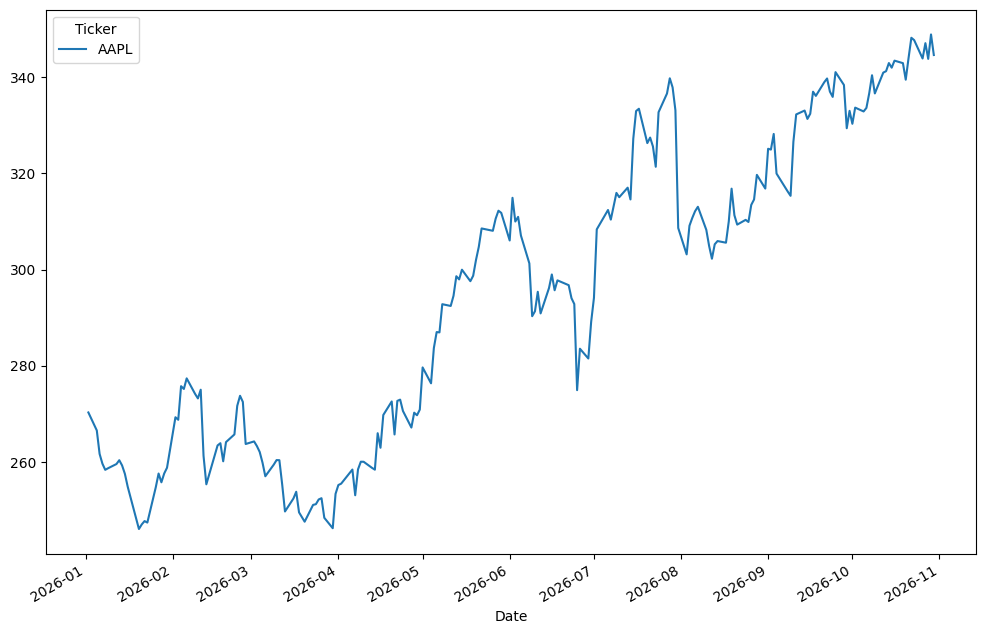

In [9]:
df.Close.plot(figsize=(12,8))

In [10]:
scalar = StandardScaler()
df["Close"] = scalar.fit_transform(df["Close"])
# fit calculates the standard deviation and mean of all the historical close prices
# transform applied standardisation formula

In [11]:
df.Close

Ticker,AAPL
Date,
2026-01-02,-0.781191
2026-01-05,-0.900431
2026-01-06,-1.056238
2026-01-07,-1.120788
2026-01-08,-1.161805
...,...
2026-10-26,1.566603
2026-10-27,1.668313
2026-10-28,1.564052


In [12]:
seq_lenght = 30
data = []
for i in range(len(df)-seq_lenght):
  data.append(df.Close[i:i+seq_lenght])
data = np.array(data)
train_size = int(0.8*len(data))
# tran_size basically used 80 percent of the data for training and 20 percent for testing

In [13]:
x_train = torch.from_numpy(data[:train_size,:-1,:]).float()
# everything till train_size except the last one(train_size itself) and the last colon keeps all features intact
y_train = torch.from_numpy(data[:train_size , -1,:]).float()
# represents what x_train plans to predict and , -1 indicates select only last data from the list
x_test = torch.from_numpy(data[train_size:, :-1,:]).float()
# grabs all the days except the last in th 20percent test model
y_test = torch.from_numpy(data[train_size:,-1,:]).float()
# grabs last one that we plan to predict

In [15]:



class PredictionModel(nn.Module):
  # creates custom neural network from Pytorchs base nn.Module
  def __init__(self, input_dim, hidden_dim, num_layers, output_dim):
    # input_dim - no of features per step (only one thats close values),
    # hidden_dim - number of hidden units inside LSTM,
    # num_layers - how many stacked LSTM layers we want
    # output_dim - size of output which is one in our case as we r predicting single future stock price
    super(PredictionModel, self).__init__()
    self.hidden_dim = hidden_dim
    self.num_layers = num_layers
    self.lstm = nn.LSTM(input_dim, hidden_dim, num_layers, batch_first=True)
    self.fc = nn.Linear(hidden_dim, output_dim)


  def forward(self, x):
    h0 = torch.zeros(
        self.num_layers, x.size(0), self.hidden_dim, device=x.device
    )
    # short term memory, tracks what happened the most recent
    c0 = torch.zeros(
        self.num_layers, x.size(0), self.hidden_dim, device=x.device
    )
    # long term memory, like the important patterns accross 30 days
    out, (hn, cn) = self.lstm(x, (h0.detach(), c0.detach()))
    # self.lstm passes data into the LSTM layer we created and take 2 inputs , x is the input data, h0 and c0(short and long term memory)
    # detach cuts off history from previous step
    out = self.fc(out[:, -1, :])
    # takes only the last day we plan to predict and uses all features to predict
    return out

In [16]:
model = PredictionModel(input_dim = 1,hidden_dim = 32, num_layers = 2, output_dim = 1)
# input is only one(close data), hidden_dim is basically the brain power ,32 is lightweight in this case, 2 LSTM layers so
# more better pattern recognition and 1 output

In [17]:
criterion = nn.MSELoss()
# MSELoss means mean squared error loss
# after the model makes a prediction, this function comapres it to the actual value, if the value is off by a bit penalty is small
# and penalty is big for big deviation(because the difference is squared)
optimizer = optim.Adam(model.parameters(), lr = 0.01)
# this function tweaks the errors in the model to fix mistakes
# lr is the learning rate, 0.01 is moderate, too high then it might jump past the best setting , too low then it might take forever to learn

In [18]:
num_epochs = 200
# model will test dataset 200 times
for i in range(num_epochs):
  y_train_pred = model(x_train)
# feeds training input into the LSTM model
  loss = criterion(y_train_pred, y_train)
# calculates error
  if i % 25 == 0:
    # prints updates every 25
    print(i, loss.item())

  optimizer.zero_grad()
  # resets all the accumulated gradient value to 0
  loss.backward()
  # finds who caused the mistake
  optimizer.step()
  # updates and corrects the model

0 0.6586765050888062
25 0.06586279720067978
50 0.038631342351436615
75 0.0279004517942667
100 0.023769352585077286
125 0.023398369550704956
150 0.022941144183278084
175 0.021195920184254646


In [19]:
model.eval()
# puts pytorch model in evaluation mode
y_test_pred = model(x_test)
# passes the 20 percent of the data we kept aside for testing to generate the prediction(y_test)

y_train_pred = scalar.inverse_transform(y_train_pred.detach().cpu().numpy())
# scalar.inverse_transform - earlier we stored data between value 0 to 1 so we r inverse scaling to real life prices
y_train = scalar.inverse_transform(y_train.detach().cpu().numpy())
y_test_pred = scalar.inverse_transform(y_test_pred.detach().cpu().numpy())
y_test = scalar.inverse_transform(y_test.detach().cpu().numpy())

In [20]:
train_rmse = root_mean_squared_error(y_train[:,0], y_train_pred[:,0])
test_rmse = root_mean_squared_error(y_test[:,0], y_test_pred[:,0])
# rmse - root mean  squared error means how far our prediction is from the actual figure hence the lower the better


In [26]:
train_rmse

4.374003887176514

In [27]:
test_rmse

6.331170082092285

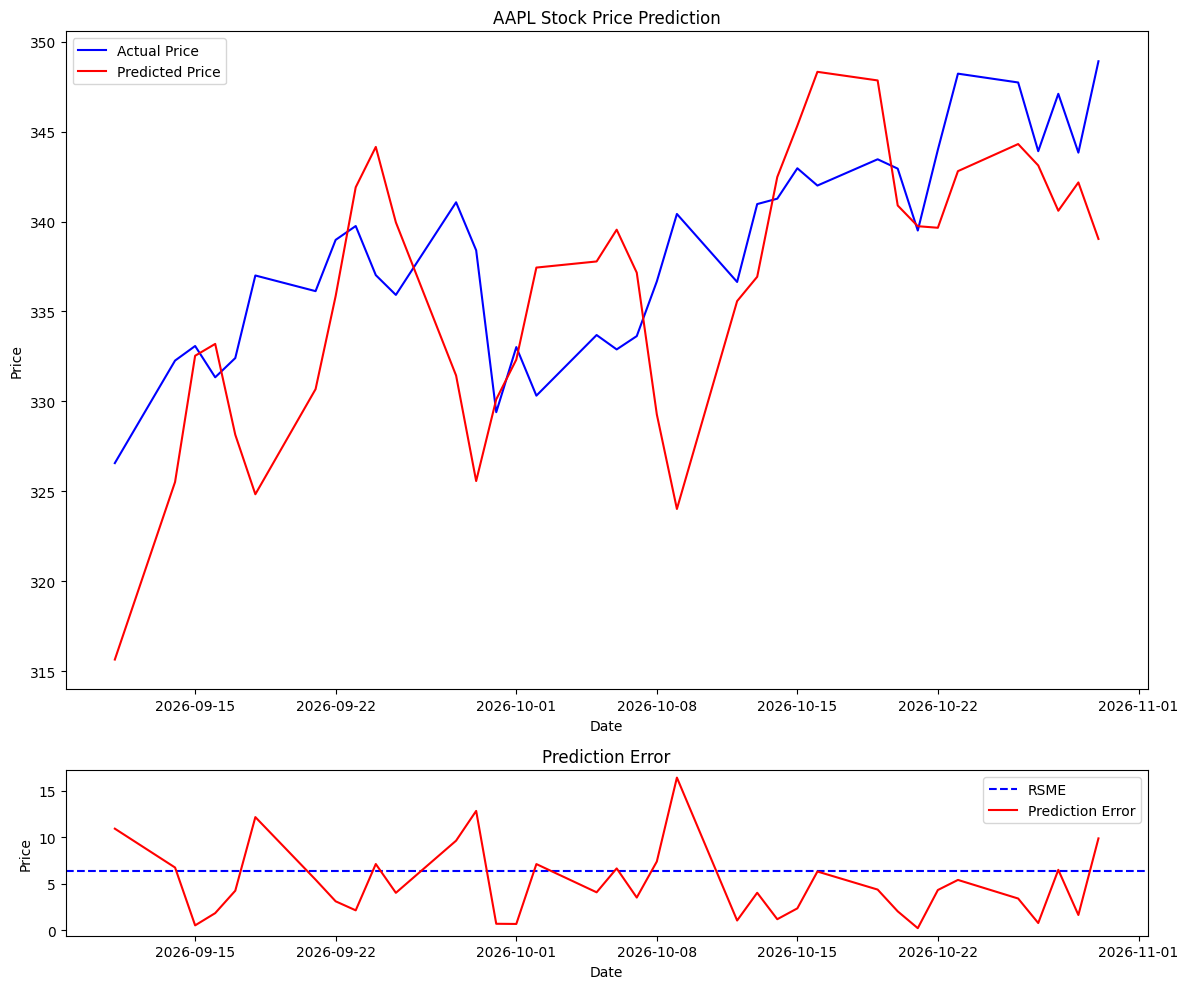

In [32]:
fig = plt.figure(figsize = (12,10))

gs = fig.add_gridspec(4,1)

axl = fig.add_subplot(gs[:3,0])
axl.plot(df.iloc[-len(y_test) : ].index, y_test, color = "blue", label = 'Actual Price')
axl.plot(df.iloc[-len(y_test):].index, y_test_pred, color = "red", label = 'Predicted Price')
axl.legend()
plt.title(f"{ticker} Stock Price Prediction")
plt.xlabel("Date")
plt.ylabel("Price")

ax2 = fig.add_subplot(gs[3,0])
ax2.axhline(test_rmse, color = "blue", linestyle = '--', label="RSME")
ax2.plot(df[-len(y_test):].index, abs(y_test - y_test_pred), "r", label = 'Prediction Error')
ax2.legend()
plt.title("Prediction Error")
plt.xlabel("Date")
plt.ylabel("Price")
plt.tight_layout()
plt.show()